# 05 – Optimisation and performance
Measures where the pipeline spends its time and memory, makes two targeted optimisations, verifies they give identical results, and estimates the arithmetic work (FLOPs) and arithmetic intensity of each model's predictions (as in the Week 2 roofline workshop).

All timings are wall-clock on this computer, repeated to show variability. Absolute numbers will differ between machines; the ratios (speed-ups) are what matter.

⏱ Takes about 5 minutes.

In [1]:
import sys
sys.path.insert(0, "../src")

import cProfile, io, pstats, time
from itertools import islice
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from occforecast.load import load_occupancy, load_cached, parse_timestamps, REQUIRED_COLUMNS
from occforecast.resample import resample_all, to_regular, to_regular_naive
from occforecast.model import make_features, make_model, FEATURES

DATA = "../data/raw/5occupancySensor_MayToDec2024_9MRows.csv"
SPLIT = pd.Timestamp("2025-07-01", tz="Australia/Melbourne")
Path("../data/processed").mkdir(exist_ok=True)

def timeit(fn, repeats=3):
    """Run fn `repeats` times; return (mean seconds, std seconds, last result)."""
    times, out = [], None
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - t0)
    return float(np.mean(times)), float(np.std(times)), out

def mb(df):
    """Memory used by a DataFrame in MB (including string contents)."""
    return df.memory_usage(deep=True).sum() / 1e6

# A 1M-row extract of the raw file, used where reading the whole file the slow
# way would take too long or too much memory.
N = 1_000_000
subset = Path("../data/processed/occ_first_1M.csv")
if not subset.exists():
    with open(DATA) as src, open(subset, "w") as dst:
        dst.writelines(islice(src, N + 1))          # header + first N rows

## 1. Where does the time go? (end-to-end timing)
Each step of the pipeline is timed 3 times (the CSV load once more for the profile below). Model steps use Space A with the notebook-03 split.

In [2]:
timing = []
def record(step, fn, repeats=3):
    m, s, out = timeit(fn, repeats)
    timing.append({"Step": step, "Mean (s)": m, "Std (s)": s, "Repeats": repeats})
    print(f"{step:<32} {m:7.2f} ± {s:.2f} s")
    return out

events = record("Load + clean CSV (full file)", lambda: load_occupancy(DATA))
series = record("Resample to 15 min (all spaces)", lambda: resample_all(events, freq="15min", max_hold="48h").sort_index())
labels = {s: f"Space {chr(65 + i)}" for i, s in enumerate(sorted(events["space"].unique()))}
ys = {labels[sp]: g["headcount_mean"] for sp, g in series.groupby("space")}
record("Build features (all spaces)", lambda: {k: make_features(y) for k, y in ys.items()})

y = ys["Space A"]
X = make_features(y)
train = (y.index < SPLIT) & y.notna().to_numpy()
test = y.index >= SPLIT
fitted = {}
for m, name in [("linear", "Linear regression"), ("tree", "Decision tree"), ("mlp", "Neural network (MLP)")]:
    fitted[m] = record(f"Train {name} (Space A)", lambda m=m: make_model(m).fit(X[train], y[train]))
    record(f"Predict {name} (Space A)", lambda m=m: fitted[m].predict(X[test]), repeats=5)

timing = pd.DataFrame(timing).set_index("Step")
display(timing.round(3))

Load + clean CSV (full file)       12.48 ± 0.18 s
Resample to 15 min (all spaces)     4.27 ± 0.04 s
Build features (all spaces)         3.56 ± 0.08 s
Train Linear regression (Space A)    0.05 ± 0.01 s
Predict Linear regression (Space A)    0.00 ± 0.00 s
Train Decision tree (Space A)       0.19 ± 0.00 s
Predict Decision tree (Space A)     0.00 ± 0.00 s
Train Neural network (MLP) (Space A)    9.77 ± 0.02 s
Predict Neural network (MLP) (Space A)    0.01 ± 0.00 s


,Mean (s),Std (s),Repeats
Step,,,
Load + clean CSV (full file),12.482,0.176,3
Resample to 15 min (all spaces),4.274,0.045,3
Build features (all spaces),3.563,0.079,3
Train Linear regression (Space A),0.048,0.014,3
Predict Linear regression (Space A),0.004,0.000,5
Train Decision tree (Space A),0.194,0.002,3
Predict Decision tree (Space A),0.005,0.000,5
Train Neural network (MLP) (Space A),9.766,0.021,3
Predict Neural network (MLP) (Space A),0.007,0.000,5


**Findings:** loading and cleaning the 1.6 GB CSV is the slowest step (12.5 ± 0.2 s), followed by MLP training (9.8 s per space), resampling (4.3 s) and feature building (3.6 s). Training linear regression (0.05 s) and the decision tree (0.19 s) is negligible, and every model predicts a full test period (≈ 28,000 intervals) in under 10 ms. Run-to-run variation is small (standard deviation ≤ 1.5% for the slow steps), so the timings are reliable. The optimisation effort therefore targets data loading and model choice, not prediction.

## 2. Profiling the loading step
`cProfile` records how long is spent inside every function. Here it profiles a straightforward loader – read the needed columns and convert timestamps with `pd.to_datetime` – on the first 1M rows. Sorting by `tottime` (time spent inside each function itself) shows which operation is the bottleneck.

In [3]:
def original_load(path):
    """First version of the loader: standard pandas timestamp parsing."""
    df = pd.read_csv(path, usecols=REQUIRED_COLUMNS)
    df["time"] = pd.to_datetime(df["collecteddate"], utc=True, errors="coerce")
    return df

prof = cProfile.Profile()
prof.enable()
_ = original_load(subset)
prof.disable()
buf = io.StringIO()
pstats.Stats(prof, stream=buf).strip_dirs().sort_stats("tottime").print_stats(10)   # time inside each function
print(buf.getvalue()[:3500])

         4612 function calls (4581 primitive calls) in 0.893 seconds

   Ordered by: internal time
   List reduced from 435 to 10 due to restriction <10>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.507    0.507    0.521    0.521 c_parser_wrapper.py:281(read)
        1    0.319    0.319    0.321    0.321 datetimes.py:507(_array_strptime_with_fallback)
        9    0.023    0.003    0.035    0.004 construction.py:580(sanitize_array)
        4    0.012    0.003    0.012    0.003 concat.py:56(concat_compat)
        5    0.010    0.002    0.010    0.002 string_.py:764(_from_sequence)
      2/1    0.007    0.004    0.007    0.007 {built-in method numpy.array}
        1    0.005    0.005    0.335    0.335 datetimes.py:834(to_datetime)
        1    0.002    0.002    0.014    0.014 c_parser_wrapper.py:474(_concatenate_chunks)
        1    0.001    0.001    0.001    0.001 datetimes.py:2736(_construct_from_dt64_naive)
        4    0.000    0.000    0.00

**Findings:** of 0.89 s to load 1M rows, 0.51 s (57%) is spent in pandas' C parser reading the CSV text (`c_parser_wrapper.read`) and 0.32 s (36%) converting timestamp text to datetimes (`_array_strptime_with_fallback`). Everything else is small. Both are already compiled code, so the realistic options are to parse less often (cache) or parse less data (fewer columns), rather than to rewrite either step in Python.

## 3. Optimisations to loading
### 3a. A proposed optimisation that was rejected: hand-written timestamp parsing
`pd.to_datetime` can be slow when timestamps carry different UTC offsets (`+10`/`+11` with daylight saving), so a hand-written parser, `parse_timestamps`, was written that handles the date-time part and the offset separately. It gives identical results (unit test, and checked again below on 1M real timestamps). **Whether it is faster had to be measured, not assumed:** it was faster on the synthetic test data and newer pandas version used during development, but not on this machine with the real data.

In [4]:
text = pd.read_csv(subset, usecols=["collecteddate"])["collecteddate"]
t_std, s_std, parsed_std = timeit(lambda: pd.to_datetime(text, utc=True, errors="coerce"))
t_fast, s_fast, parsed_fast = timeit(lambda: parse_timestamps(text))
same = ((parsed_std == parsed_fast) | (parsed_std.isna() & parsed_fast.isna())).all()
print(f"pd.to_datetime:    {t_std:.2f} ± {s_std:.2f} s for {len(text):,} timestamps")
ratio = t_std / t_fast
print(f"parse_timestamps:  {t_fast:.2f} ± {s_fast:.2f} s   -> "
      + (f"{ratio:.1f}x faster" if ratio > 1 else f"{1 / ratio:.1f}x SLOWER - not adopted; load_occupancy keeps pd.to_datetime"))
print(f"Identical results: {same}")

pd.to_datetime:    0.32 ± 0.01 s for 1,000,000 timestamps
parse_timestamps:  0.93 ± 0.01 s   -> 2.9x SLOWER - not adopted; load_occupancy keeps pd.to_datetime
Identical results: True


**Findings:** the hand-written parser gives identical results on 1M real timestamps but is **2.9× slower** (0.93 s vs 0.32 s), so it was rejected and `load_occupancy` keeps `pd.to_datetime`. It had appeared ≈ 3× faster during development, on synthetic data with shuffled `+10`/`+11` offsets and a newer pandas version. This shows that a speed-up measured in one setting cannot be assumed to carry over: performance claims must be measured on the real data and machine.

### 3b. Fewer columns and compact types (memory)
**Baseline:** read every column with default types (what a first attempt would do).
**Optimised (`load_occupancy`):** read only the 4 needed columns, in chunks, and store space/status as categories and headcount as a 16-bit integer.

Measured on the same 1M rows (reading all 9.1M rows with every column could exhaust a laptop's memory); memory is then scaled to the full file.

In [5]:
def naive_load(path):
    df = pd.read_csv(path)                            # all columns, default types
    df["collecteddate"] = pd.to_datetime(df["collecteddate"], utc=True)
    return df

t_naive, s_naive, df_naive = timeit(lambda: naive_load(subset))
t_opt, s_opt, df_opt = timeit(lambda: load_occupancy(subset))
scale = len(events) / N
load_cmp = pd.DataFrame({
    "Time, 1M rows (s)": [t_naive, t_opt],
    "Memory, 1M rows (MB)": [mb(df_naive), mb(df_opt)],
    "Memory, est. full file (MB)": [mb(df_naive) * scale, mb(df_opt) * scale],
    "Columns kept": [df_naive.shape[1], df_opt.shape[1]],
}, index=["Baseline: all columns, default types", "Optimised: 4 columns, compact types"])
display(load_cmp.round(2))
print(f"Memory reduction: {mb(df_naive) / mb(df_opt):.1f}x   Time ratio: {t_naive / t_opt:.2f}x")
print(f"Actual memory of the full cleaned events table: {mb(events):.0f} MB")

,"Time, 1M rows (s)","Memory, 1M rows (MB)","Memory, est. full file (MB)",Columns kept
"Baseline: all columns, default types",0.92,432.46,3931.78,8
"Optimised: 4 columns, compact types",1.23,12.00,109.11,4


Memory reduction: 36.0x   Time ratio: 0.75x
Actual memory of the full cleaned events table: 109 MB


### 3c. Caching the cleaned data
`load_cached` saves the cleaned table once in a binary format (pickle) and reloads it on later runs, instead of re-parsing the CSV every time a notebook starts.

In [6]:
cache = Path("../data/processed/occupancy.clean.pkl")
cache.unlink(missing_ok=True)
t_first, _, _ = timeit(lambda: load_cached(DATA, cache=cache), repeats=1)    # parses CSV and saves
t_cached, s_cached, ev_cached = timeit(lambda: load_cached(DATA, cache=cache))
assert ev_cached.attrs["from_cache"]
pd.testing.assert_frame_equal(ev_cached, events)                          # identical data
print(f"First run (parse CSV + save): {t_first:.1f} s")
print(f"Later runs (read cache):      {t_cached:.2f} ± {s_cached:.2f} s   -> {t_first / t_cached:.0f}x faster")
print(f"Cache file size: {cache.stat().st_size / 1e6:.0f} MB (CSV: {Path(DATA).stat().st_size / 1e6:.0f} MB)")

First run (parse CSV + save): 12.7 s
Later runs (read cache):      0.03 ± 0.00 s   -> 389x faster
Cache file size: 109 MB (CSV: 1605 MB)


**Findings (3b):** reading only the 4 needed columns and storing them compactly cuts memory **36×**: 12 MB instead of 432 MB per million rows, i.e. ≈ 109 MB instead of an estimated **3.9 GB** for the full file. On this laptop (≈ 2.3 GB free while working) the naive approach would likely not fit in memory at all. The cost is a slightly slower read (1.23 s vs 0.92 s per million rows) because of chunked reading and type conversion: a deliberate trade of a little time for a large memory saving.

**Findings (3c):** caching the cleaned table reduces load time from 12.7 s to **0.03 s (≈ 390× faster)** on every run after the first. `assert_frame_equal` confirms the cached data is identical to a fresh load. The cache file is 109 MB, 15× smaller than the 1.6 GB CSV.

## 4. Optimisation – resampling: loops vs vectorised
`to_regular_naive` walks through events one at a time in plain Python; `to_regular` (used everywhere) does the same calculation with whole-array pandas/NumPy operations. They were written independently, so identical output is also a **verification** of both. Measured on increasing numbers of events from Space A.

In [7]:
evA = events[events["space"] == sorted(events["space"].unique())[0]]
rows = []
for n in [10_000, 50_000, 200_000]:
    sub = evA.iloc[:n]
    t_loop, _, slow = timeit(lambda: to_regular_naive(sub, max_hold="48h"), repeats=1)
    t_vec, _, fast = timeit(lambda: to_regular(sub, max_hold="48h"), repeats=3)
    pd.testing.assert_frame_equal(fast, slow, check_freq=False, rtol=1e-9)   # same answer
    rows.append({"Events": n, "Loop (s)": t_loop, "Vectorised (s)": t_vec, "Speed-up": t_loop / t_vec})
res_cmp = pd.DataFrame(rows).set_index("Events")
display(res_cmp.round(3))

per_event = res_cmp["Loop (s)"].iloc[-1] / res_cmp.index[-1]
print(f"Outputs identical in all cases. Estimated loop time for all {len(events):,} events: "
      f"{per_event * len(events) / 60:.1f} min (vectorised: {timing.loc['Resample to 15 min (all spaces)', 'Mean (s)']:.1f} s)")

,Loop (s),Vectorised (s),Speed-up
Events,,,
10000,0.018,0.007,2.475
50000,0.082,0.017,4.959
200000,0.300,0.049,6.128


Outputs identical in all cases. Estimated loop time for all 9,091,732 events: 0.2 min (vectorised: 4.3 s)


**Findings:** the vectorised resampler gives **identical output** to the independent loop version in every case, which verifies both. Its speed-up grows with data size, from 2.5× (10,000 events) to **6.1× (200,000 events)**, because its fixed overhead is spread over more events. For the full 9.1M events the loop would take an estimated ≈ 14 s against 4.3 s vectorised (≈ 3×). The gain is real but modest: the loop does very little work per event, and the vectorised version also has to build every 15-minute interval. Resampling was not a bottleneck either way.

## 5. FLOPs and arithmetic intensity of model predictions
**FLOPs per forecast** are counted from the fitted models (one floating-point add or multiply = 1 FLOP):
- *Linear:* standardise 12 features (subtract, divide: 24) + 12 multiply-adds + intercept (≈ 24) → **≈ 48 FLOPs**.
- *MLP:* standardise (24) + for each layer `2 × inputs × outputs` (multiply-add) + biases + ReLU activations.
- *Decision tree:* no arithmetic, only one comparison per level visited (reported as comparisons).

**Bytes per forecast:** each forecast reads one row of 12 features (12 × 8 bytes) and writes one 8-byte result = 104 bytes. Model weights are small enough to stay in the CPU cache, so they are not counted as memory traffic.

**Arithmetic intensity** = FLOPs ÷ bytes moved. Low intensity means speed is limited by memory bandwidth; high intensity means it is limited by the processor's arithmetic rate.

In [8]:
n_feat = len(FEATURES)
bytes_per = n_feat * 8 + 8
mlp = fitted["mlp"].named_steps["model"]
layer_flops = [2 * w.shape[0] * w.shape[1] + w.shape[1] for w in mlp.coefs_]   # multiply-adds + bias
relu_flops = sum(w.shape[1] for w in mlp.coefs_[:-1])                          # hidden activations
flops = {"Linear regression": 2 * n_feat + 2 * n_feat + 1,
         "Neural network (MLP)": 2 * n_feat + sum(layer_flops) + relu_flops}
tree = fitted["tree"].named_steps["model"]
X_test_imp = fitted["tree"].named_steps["impute"].transform(X[test])
comparisons = tree.decision_path(X_test_imp).sum(axis=1).mean() - 1             # internal nodes visited

n_pred = int(test.sum())
rows = []
for m, name in [("linear", "Linear regression"), ("mlp", "Neural network (MLP)"), ("tree", "Decision tree")]:
    t = timing.loc[f"Predict {name} (Space A)", "Mean (s)"]
    f = flops.get(name, np.nan)
    rows.append({"Model": name,
                 "FLOPs per forecast": f,
                 "Comparisons per forecast": comparisons if m == "tree" else 0,
                 "Arithmetic intensity (FLOP/byte)": f / bytes_per,
                 "Forecasts per second": n_pred / t,
                 "Achieved GFLOP/s": f * n_pred / t / 1e9})
ai = pd.DataFrame(rows).set_index("Model")
display(ai.round(3))
print(f"MLP layers: {[w.shape for w in mlp.coefs_]}, trained for {mlp.n_iter_} epochs")

,FLOPs per forecast,Comparisons per forecast,Arithmetic intensity (FLOP/byte),Forecasts per second,Achieved GFLOP/s
Model,,,,,
Linear regression,49.0,0.000,0.471,7217759.759,0.354
Neural network (MLP),1945.0,0.000,18.702,4031699.634,7.842
Decision tree,NaN,9.872,NaN,6274290.712,NaN


MLP layers: [(12, 32), (32, 16), (16, 1)], trained for 129 epochs


### Roofline plot
The roofline shows the best possible speed for a given arithmetic intensity: the slanted line is the memory-bandwidth limit, the flat line the processor's peak arithmetic rate.

The two limits below are for the computer used (AMD Ryzen 9 6900HX, 16 GB DDR5-4800 dual-channel), from Task Manager → Performance. Peak GFLOP/s ≈ cores × clock (GHz) × FLOPs per cycle per core (16 for double precision on a CPU with AVX2 + FMA). Peak bandwidth (GB/s) ≈ memory speed (MT/s) × 8 bytes × number of channels ÷ 1000.

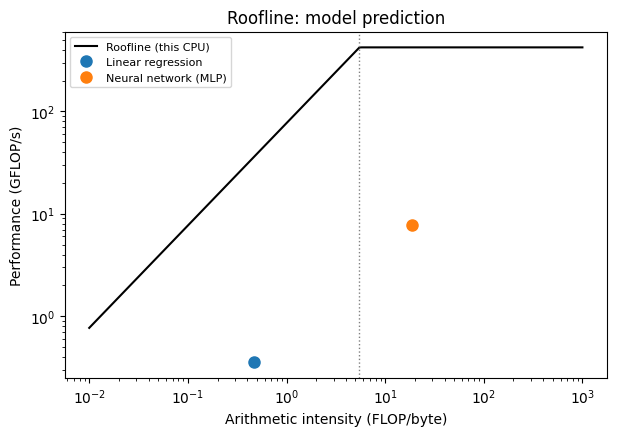

Ridge point (memory-bound below, compute-bound above): 5.5 FLOP/byte


In [9]:
PEAK_GFLOPS = 422.0     # Ryzen 9 6900HX: 8 cores x 3.3 GHz (base) x 16 FLOP/cycle (AVX2 FMA, double)
PEAK_BW_GBS = 76.8      # DDR5-4800, 2 channels: 4800 MT/s x 8 bytes x 2 / 1000

x = np.logspace(-2, 3, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(x, np.minimum(PEAK_GFLOPS, PEAK_BW_GBS * x), color="black", lw=1.5, label="Roofline (this CPU)")
for name, r in ai.dropna(subset=["Achieved GFLOP/s"]).iterrows():
    if r["Arithmetic intensity (FLOP/byte)"] > 0:
        ax.loglog(r["Arithmetic intensity (FLOP/byte)"], r["Achieved GFLOP/s"], "o", ms=8, label=name)
ax.axvline(PEAK_GFLOPS / PEAK_BW_GBS, color="grey", ls=":", lw=1)
ax.set_xlabel("Arithmetic intensity (FLOP/byte)"); ax.set_ylabel("Performance (GFLOP/s)")
ax.set_title("Roofline: model prediction"); ax.legend(fontsize=8); plt.show()
print(f"Ridge point (memory-bound below, compute-bound above): {PEAK_GFLOPS / PEAK_BW_GBS:.1f} FLOP/byte")

**Findings:** linear regression does 49 FLOPs per forecast at an arithmetic intensity of 0.47 FLOP/byte, left of the ridge point (5.5 FLOP/byte), so it is **memory-bound**: its ceiling is 76.8 × 0.47 ≈ 36 GFLOP/s, and it achieves 0.35 GFLOP/s (≈ 1%). The MLP does 1,945 FLOPs per forecast at 18.7 FLOP/byte, so it is **compute-bound**: its ceiling is 422 GFLOP/s, and it achieves 7.8 GFLOP/s (≈ 2%). The decision tree does no arithmetic, only ≈ 10 comparisons per forecast. All points are far below the roof because each prediction does so little work that fixed overheads dominate: scikit-learn's input checks, the pipeline's imputer and scaler each creating new arrays (so far more than 104 bytes per forecast actually move through memory), and matrices too small (12×32) for the maths library to run efficiently. In practice this does not matter: every model already makes 4–7 million forecasts per second.

## 6. Summary: baseline vs final

In [10]:
loop_full = per_event * len(events)
summary = pd.DataFrame([
    {"Step": "Load data (full file)", "Baseline": f"{t_first:.1f} s (parse CSV every run)",
     "Final": f"{t_cached:.2f} s (cached)", "Improvement": f"{t_first / t_cached:.0f}x faster"},
    {"Step": "Parse 1M timestamps (rejected idea)", "Baseline": f"{t_std:.2f} s (pd.to_datetime, kept)",
     "Final": f"{t_fast:.2f} s (parse_timestamps)",
     "Improvement": f"{t_std / t_fast:.1f}x faster" if t_std > t_fast else f"{t_fast / t_std:.1f}x slower - not adopted"},
    {"Step": "Memory of loaded data", "Baseline": f"{mb(df_naive) * scale:,.0f} MB (est., all columns)",
     "Final": f"{mb(events):,.0f} MB", "Improvement": f"{mb(df_naive) * scale / mb(events):.1f}x less"},
    {"Step": "Resample (all events)", "Baseline": f"{loop_full / 60:.1f} min (est., Python loop)",
     "Final": f"{timing.loc['Resample to 15 min (all spaces)', 'Mean (s)']:.1f} s (vectorised)",
     "Improvement": f"{loop_full / timing.loc['Resample to 15 min (all spaces)', 'Mean (s)']:.0f}x faster"},
    {"Step": "Train model (per space)", "Baseline": f"{timing.loc['Train Neural network (MLP) (Space A)', 'Mean (s)']:.1f} s (MLP)",
     "Final": f"{timing.loc['Train Linear regression (Space A)', 'Mean (s)']:.2f} s (linear, ≈ same accuracy)",
     "Improvement": f"{timing.loc['Train Neural network (MLP) (Space A)', 'Mean (s)'] / timing.loc['Train Linear regression (Space A)', 'Mean (s)']:.0f}x faster"},
]).set_index("Step")
display(summary)

,Baseline,Final,Improvement
Step,,,
Load data (full file),12.7 s (parse CSV every run),0.03 s (cached),389x faster
Parse 1M timestamps (rejected idea),"0.32 s (pd.to_datetime, kept)",0.93 s (parse_timestamps),2.9x slower - not adopted
Memory of loaded data,"3,932 MB (est., all columns)",109 MB,36.0x less
Resample (all events),"0.2 min (est., Python loop)",4.3 s (vectorised),3x faster
Train model (per space),9.8 s (MLP),"0.05 s (linear, ≈ same accuracy)",203x faster


**Findings:** the bottlenecks were data loading (12.5 s) and MLP training (9.8 s per space), not prediction. The largest gains came from avoiding repeated work and unnecessary data rather than faster arithmetic. Caching made repeat loads **≈ 390× faster**, reading only the needed columns with compact types used **36× less memory** (≈ 109 MB instead of ≈ 3.9 GB), and choosing linear regression over the MLP trains **≈ 200× faster** for nearly the same accuracy (notebook 04). Vectorised resampling is ≈ 3× faster than a plain loop over the full data. One proposed optimisation, a hand-written timestamp parser, was measured to be 2.9× slower on this machine and was rejected. Correctness was checked after every change: the cached data is identical to a fresh load, the vectorised and loop resamplers give identical output, the alternative parser matches `pd.to_datetime`, and the full unit-test suite passes.